# Notebook 05 — Roteiro comparativo de agrupamento (clustering) — CPC 2023

**Objetivo:** investigar diferentes representações dos cursos, variar **K = 2 a 20**, avaliar qualidade e estabilidade e produzir gráficos e tabelas para discussão acadêmica. Começar pela **base completa** e reutilizar o mesmo notebook para **áreas individuais**.

**Origem:** notebooks 03 e 04 fornecidos e `base_analitica_1907_cursos.csv`. O cenário de quatro dimensões replica exatamente os pesos do notebook 03. **Não são resultados conclusivos**: a comparação temporal (cenários B e C) permanece futura.

**Sequência de execução:** execute as células em ordem. A varredura exploratória utiliza poucas divisões por padrão para reduzir o tempo; a avaliação detalhada utiliza 30 repetições para os valores de K selecionados. Salve o notebook antes de começar.

**Cuidados:** silhueta e DBI são calculados no espaço de cada modelo; valores de espaços com dimensões diferentes não têm comparação direta irrestrita. CPC isolado representa estratificação de desempenho, não perfis multidimensionais. A estabilidade ARI compara atribuições nos mesmos cursos e não valida rótulos verdadeiros. Treino e teste são separados, e as transformações são ajustadas apenas no treino.

## 1 — Configurações e carregamento

Ajuste `ESCOPO` para `"BASE_COMPLETA"` ou `"AREA"`. Para `AREA`, informe um valor existente em `Area_2023` (por exemplo, `"Engenharia Civil"`). As saídas serão separadas por escopo.

In [1]:
from pathlib import Path
import re, time, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, davies_bouldin_score, adjusted_rand_score

ANO = 2023
ESCOPO = "BASE_COMPLETA"   # "BASE_COMPLETA" ou "AREA"
AREA_ESCOLHIDA = "Engenharia Civil"  # só usado em ESCOPO="AREA"
K_VALORES = list(range(2, 21))
SEMENTES_EXPLORACAO = list(range(42, 47))  # 5 divisões na exploração; ajuste se desejar
SEMENTES_CONFIRMACAO = list(range(42, 72)) # 30 divisões na avaliação detalhada
TEST_SIZE = 0.20
N_INIT = 20
SEMENTE_KMEANS = 42
SILHUETA_AMOSTRA = 500  # acelera conjuntos grandes; use None para cálculo integral
PCA_COMPONENTES = 2
K_PARA_DETALHAR = {"C1_CPC": 4, "C2_8IND": 4, "C3_4DIM": 4, "C4_PCA": 4}  # editar APÓS explorar K
CODIGO_IES_PUC = 528
CODIGO_CURSO_CIVIL_PUC = 29445

PASTA_PROJETO = Path.cwd()
ARQUIVO = PASTA_PROJETO / 'dados' / 'processados' / 'base_analitica_1907_cursos.csv'
if not ARQUIVO.is_file():
    ARQUIVO = PASTA_PROJETO / 'base_analitica_1907_cursos.csv'
if not ARQUIVO.is_file():
    raise FileNotFoundError('Coloque a base em dados/processados/ ou na pasta do notebook: ' + str(PASTA_PROJETO))
df_base = pd.read_csv(ARQUIVO, encoding='utf-8-sig')
df_base.columns = df_base.columns.str.replace('\ufeff', '', regex=False).str.strip()
print('Arquivo:', ARQUIVO)
print('Dimensões:', df_base.shape)
print('Áreas disponíveis:', df_base['Area_2023'].nunique(dropna=True))
print('Duplicatas por IES e curso:', df_base.duplicated(['Código da IES', 'Código do Curso']).sum())
display(df_base.head(3))

Arquivo: g:\Meu Drive\Mestrado _ Eng_Ind\IND2622 - Ciencia de dados para processos de negocios\Trabalho final - CPC (escolhido)\Projeto_CPC_PUC_Rio_2026\dados\processados\base_analitica_1907_cursos.csv
Dimensões: (1907, 35)
Áreas disponíveis: 10
Duplicatas por IES e curso: 0


,Código da IES,Código do Curso,Modalidade_2017,Area_2017,Modalidade_2019,Area_2019,Modalidade_2023,Area_2023,CPC_2017,CPC_2019,...,Infraestrutura_2019,Enade_2023,IDD_2023,Mestres_2023,Doutores_2023,Regime_Trabalho_2023,Organizacao_Didatica_2023,Infraestrutura_2023,Oportunidades_2019,Oportunidades_2023
0,1,44,Educação Presencial,21,Educação Presencial,21,Educação Presencial,21,2.8917,3.216,...,0.450,4.191,3.488,3.750,2.917,5.0,2.640,1.396,2.476,3.44
1,2,132,Educação Presencial,21,Educação Presencial,21,Educação Presencial,21,3.2611,3.220,...,1.335,4.231,4.144,4.922,4.501,5.0,3.111,2.933,3.287,3.92
2,2,1138293,Educação Presencial,21,Educação Presencial,21,Educação Presencial,21,2.9394,3.194,...,0.854,4.194,4.187,4.907,4.519,5.0,3.120,2.866,3.166,3.86


## 2 — Elegibilidade e variáveis

Para comparar os cenários **na mesma população**, adotamos casos completos em CPC e nos oito indicadores de 2023. Não imputamos zeros. Registros excluídos serão contabilizados. Em análises por área, o número de cursos elegíveis pode impedir valores altos de K.

In [2]:
INDICADORES = ['Enade_2023','IDD_2023','Mestres_2023','Doutores_2023',
               'Regime_Trabalho_2023','Organizacao_Didatica_2023',
               'Infraestrutura_2023','Oportunidades_2023']
COLUNAS_MODELO = ['CPC_2023'] + INDICADORES
faltantes = [c for c in COLUNAS_MODELO + ['Area_2023'] if c not in df_base.columns]
if faltantes:
    raise ValueError('Colunas ausentes: ' + str(faltantes))
if ESCOPO == 'BASE_COMPLETA':
    df_escopo = df_base.copy()
    nome_escopo = 'BASE_COMPLETA'
elif ESCOPO == 'AREA':
    df_escopo = df_base.loc[df_base['Area_2023'].astype(str).str.strip().eq(AREA_ESCOLHIDA)].copy()
    nome_escopo = AREA_ESCOLHIDA
else:
    raise ValueError('ESCOPO deve ser BASE_COMPLETA ou AREA')
for c in COLUNAS_MODELO:
    df_escopo[c] = pd.to_numeric(df_escopo[c], errors='coerce')
validos = np.isfinite(df_escopo[COLUNAS_MODELO].to_numpy(dtype=float)).all(axis=1)
df_analise = df_escopo.loc[validos].copy()
if df_analise.index.has_duplicates:
    df_analise = df_analise.reset_index(drop=True)
if len(df_analise) < 15:
    raise ValueError('Menos de 15 cursos elegíveis. Verifique área e dados.')
rotulo_pasta = re.sub(r'[^A-Za-z0-9_-]+', '_', nome_escopo).strip('_')
PASTA_SAIDA = PASTA_PROJETO / 'resultados_notebook_05' / rotulo_pasta
PASTA_SAIDA.mkdir(parents=True, exist_ok=True)
print('Escopo:', nome_escopo, '| antes:', len(df_escopo), '| elegíveis:', len(df_analise), '| excluídos:', len(df_escopo)-len(df_analise))
print('Pasta de saída:', PASTA_SAIDA)
print('Distribuição de áreas (primeiras 15):')
display(df_analise['Area_2023'].value_counts().head(15).to_frame('Cursos'))
display(df_escopo[COLUNAS_MODELO].isna().sum().to_frame('Ausentes'))

Escopo: BASE_COMPLETA | antes: 1907 | elegíveis: 1907 | excluídos: 0
Pasta de saída: g:\Meu Drive\Mestrado _ Eng_Ind\IND2622 - Ciencia de dados para processos de negocios\Trabalho final - CPC (escolhido)\Projeto_CPC_PUC_Rio_2026\resultados_notebook_05\BASE_COMPLETA
Distribuição de áreas (primeiras 15):


,Cursos
Area_2023,
5710,451
6208,300
21,266
5902,245
5806,234
6307,109
6008,107
5814,93
6002,54


,Ausentes
CPC_2023,0
Enade_2023,0
IDD_2023,0
Mestres_2023,0
Doutores_2023,0
Regime_Trabalho_2023,0
Organizacao_Didatica_2023,0
Infraestrutura_2023,0
Oportunidades_2023,0


## 3 — Cenários e funções reutilizáveis

- **C1:** CPC contínuo (1 dimensão).
- **C2:** oito indicadores padronizados.
- **C3:** quatro dimensões construídas segundo os pesos recuperados do notebook 03: Condições = (7,5 Organização + 5 Infraestrutura + 2,5 Oportunidades)/15; Docentes = (7,5 Mestres + 15 Doutores + 7,5 Regime)/30.
- **C4:** oito indicadores → StandardScaler → PCA com duas componentes → K-means.

O **C4** é uma hipótese experimental nova, distinta do A2 anterior (que aplicava PCA às quatro dimensões com RobustScaler).

In [3]:
def criar_dimensoes_cpc(base):
    return pd.DataFrame({
        'ENADE': base['Enade_2023'],
        'IDD': base['IDD_2023'],
        'Condicoes_Formacao': (7.5*base['Organizacao_Didatica_2023'] +
                              5.0*base['Infraestrutura_2023'] +
                              2.5*base['Oportunidades_2023']) / 15.0,
        'Corpo_Docente': (7.5*base['Mestres_2023'] +
                         15.0*base['Doutores_2023'] +
                         7.5*base['Regime_Trabalho_2023']) / 30.0
    }, index=base.index)

CENARIOS = {'C1_CPC': 'CPC isolado', 'C2_8IND': '8 indicadores',
            'C3_4DIM': '4 dimensões CPC', 'C4_PCA': '8 indicadores + PCA (2D)'}

def dados_cenario(base, cenario):
    if cenario == 'C1_CPC': return base[['CPC_2023']].copy()
    if cenario == 'C3_4DIM': return criar_dimensoes_cpc(base)
    return base[INDICADORES].copy()

def preparar(cenario, treino, teste, todos):
    bruto_treino = dados_cenario(treino, cenario)
    bruto_teste = dados_cenario(teste, cenario)
    bruto_todos = dados_cenario(todos, cenario)
    scaler = StandardScaler()
    xtr = scaler.fit_transform(bruto_treino)
    xte = scaler.transform(bruto_teste)
    xall = scaler.transform(bruto_todos)
    pca = None
    if cenario == 'C4_PCA':
        pca = PCA(n_components=PCA_COMPONENTES)
        xtr = pca.fit_transform(xtr)
        xte = pca.transform(xte)
        xall = pca.transform(xall)
    return {'treino':xtr, 'teste':xte, 'todos':xall, 'scaler':scaler,
            'pca':pca, 'colunas':list(bruto_treino.columns)}

def ajustar(xtr, k):
    return KMeans(n_clusters=k, random_state=SEMENTE_KMEANS, n_init=N_INIT).fit(xtr)

def metricas_seguras(X, y, seed=42):
    n = len(X); grupos = np.unique(y)
    if len(grupos) < 2 or len(grupos) >= n:
        return np.nan, np.nan
    # A silhueta amostrada pode falhar se a amostra omitir grupos raros.
    try:
        sil = silhouette_score(X, y, sample_size=min(SILHUETA_AMOSTRA,n) if SILHUETA_AMOSTRA else None,
                               random_state=seed)
    except ValueError:
        sil = np.nan
    try:
        db = davies_bouldin_score(X,y)
    except ValueError:
        db = np.nan
    return sil, db

print('Cenários:', CENARIOS)
print('K solicitado:', min(K_VALORES), 'a', max(K_VALORES))

Cenários: {'C1_CPC': 'CPC isolado', 'C2_8IND': '8 indicadores', 'C3_4DIM': '4 dimensões CPC', 'C4_PCA': '8 indicadores + PCA (2D)'}
K solicitado: 2 a 20


## 4 — Exploração de K (2 a 20)

A exploração utiliza as **mesmas divisões para todos os cenários**. Em cada repetição, o escalonamento e o PCA são ajustados exclusivamente no treino. No teste, grupos são atribuídos por `predict`. O Davies–Bouldin e a silhueta no teste descrevem a qualidade das atribuições em observações não utilizadas para ajustar o modelo.

**Atenção:** a varredura usa o teste para exploração e seleção de K. Portanto, as métricas desse teste **não devem ser apresentadas como uma avaliação final independente**. Para uma estimativa independente, será necessário um conjunto externo ou uma estratégia de validação aninhada.

In [4]:
inicio = time.time()
log_exploracao = []
max_k_treino = int(np.floor((1-TEST_SIZE)*len(df_analise))) - 1
K_VALIDOS = [k for k in K_VALORES if 2 <= k <= max_k_treino]
if not K_VALIDOS: raise ValueError('Não há K viável com esta quantidade de cursos.')
for semente in SEMENTES_EXPLORACAO:
    idx_tr, idx_te = train_test_split(df_analise.index, test_size=TEST_SIZE,
                                      random_state=semente, shuffle=True)
    treino, teste = df_analise.loc[idx_tr], df_analise.loc[idx_te]
    for cenario in CENARIOS:
        proc = preparar(cenario, treino, teste, df_analise)
        for k in K_VALIDOS:
            modelo = ajustar(proc['treino'], k)
            ytr = modelo.labels_
            yte = modelo.predict(proc['teste'])
            siltr, dbtr = metricas_seguras(proc['treino'], ytr, semente)
            silte, dbte = metricas_seguras(proc['teste'], yte, semente)
            log_exploracao.append({'Cenario':cenario,'K':k,'Semente':semente,
                'Silhueta_treino':siltr,'Silhueta_teste':silte,
                'DB_treino':dbtr,'DB_teste':dbte,
                'Inercia_treino':modelo.inertia_,
                'Menor_grupo_treino':np.bincount(ytr, minlength=k).min(),
                'Grupos_teste':len(np.unique(yte)),
                'PCA_variancia_explicada': (proc['pca'].explained_variance_ratio_.sum() if proc['pca'] is not None else np.nan)})
log_exploracao = pd.DataFrame(log_exploracao)
resumo_k = log_exploracao.groupby(['Cenario','K'],as_index=False).agg(
    Silhueta_teste_media=('Silhueta_teste','mean'),
    Silhueta_teste_dp=('Silhueta_teste','std'),
    Silhueta_treino_media=('Silhueta_treino','mean'),
    DB_teste_medio=('DB_teste','mean'), DB_treino_medio=('DB_treino','mean'),
    Inercia_treino_media=('Inercia_treino','mean'),
    Menor_grupo_min=('Menor_grupo_treino','min'),
    Grupos_teste_medios=('Grupos_teste','mean'),
    PCA_variancia_explicada=('PCA_variancia_explicada','mean'))
print('Execuções:',len(log_exploracao),'| tempo (s):',round(time.time()-inicio,1))
print('K válidos:',K_VALIDOS)
display(resumo_k.round(4))

Execuções: 380 | tempo (s): 110.8
K válidos: [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]


,Cenario,K,Silhueta_teste_media,Silhueta_teste_dp,Silhueta_treino_media,DB_teste_medio,DB_treino_medio,Inercia_treino_media,Menor_grupo_min,Grupos_teste_medios,PCA_variancia_explicada
0,C1_CPC,2,0.5718,0.0084,0.5764,0.5744,0.5792,513.8938,646,2.0,NaN
1,C1_CPC,3,0.5193,0.0054,0.5366,0.5800,0.5671,266.1684,364,3.0,NaN
2,C1_CPC,4,0.5307,0.0170,0.5296,0.5526,0.5467,157.4989,241,4.0,NaN
3,C1_CPC,5,0.5278,0.0199,0.5222,0.5346,0.5434,107.6294,155,5.0,NaN
4,C1_CPC,6,0.5206,0.0123,0.5314,0.5349,0.5334,75.0062,114,6.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...
71,C4_PCA,16,0.3114,0.0229,0.3386,0.8441,0.8092,668.9121,20,16.0,0.6413
72,C4_PCA,17,0.3083,0.0128,0.3348,0.8761,0.8095,631.2320,24,17.0,0.6413
73,C4_PCA,18,0.3032,0.0214,0.3328,0.8686,0.8140,598.2091,19,18.0,0.6413
74,C4_PCA,19,0.2963,0.0226,0.3365,0.8687,0.8219,570.4414,19,19.0,0.6413


## 5 — Gráficos da exploração: silhueta, Davies–Bouldin e cotovelo

Valores maiores de silhueta e menores de DBI costumam ser preferíveis **dentro do mesmo cenário**. A inércia diminui ao aumentar K e não deve ser otimizada isoladamente. Os gráficos mostram as médias das divisões exploratórias.

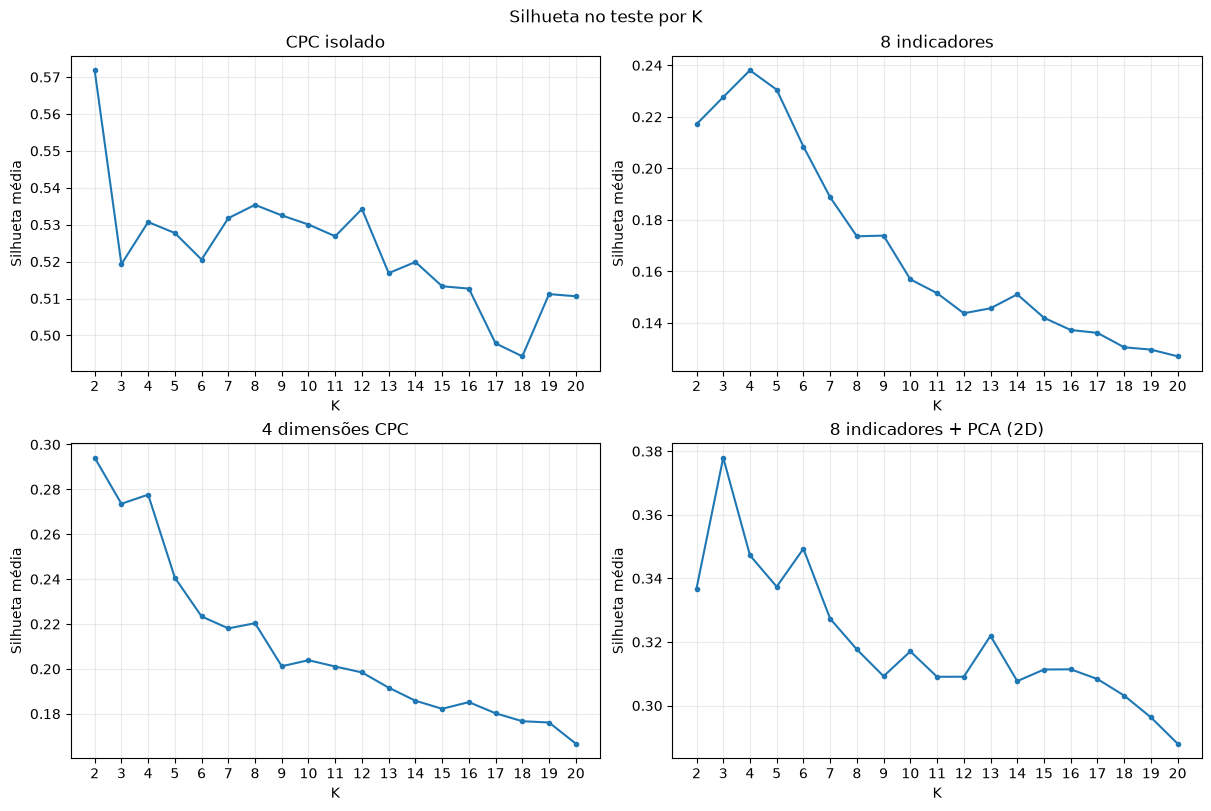

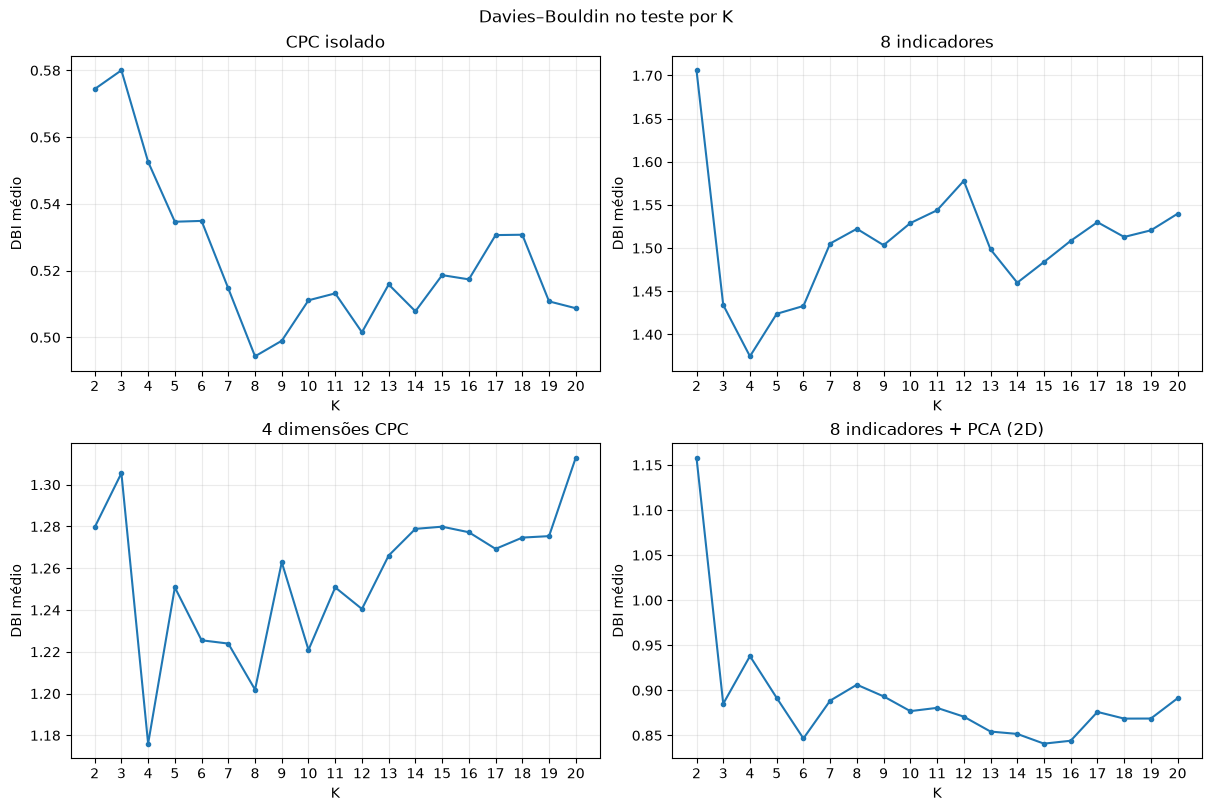

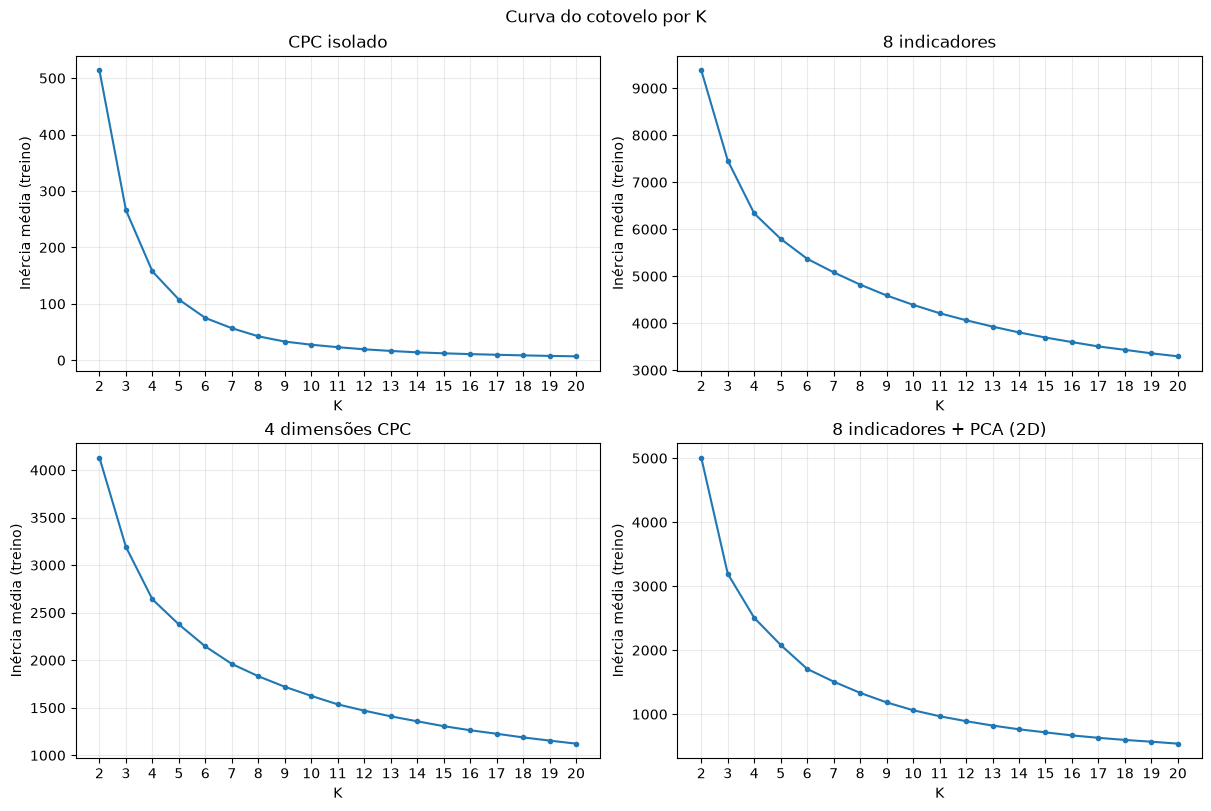

In [5]:
for metrica, titulo, ylabel, arquivo in [
    ('Silhueta_teste_media','Silhueta no teste por K','Silhueta média','01_silhueta_por_k.png'),
    ('DB_teste_medio','Davies–Bouldin no teste por K','DBI médio','02_davies_bouldin_por_k.png'),
    ('Inercia_treino_media','Curva do cotovelo por K','Inércia média (treino)','03_cotovelo_por_k.png')]:
    fig, axs = plt.subplots(2,2,figsize=(12,8),layout='constrained')
    for ax, (cen, descricao) in zip(axs.flat,CENARIOS.items()):
        z=resumo_k[resumo_k.Cenario.eq(cen)]
        ax.plot(z.K,z[metrica],marker='o',ms=3)
        ax.set_title(descricao)
        ax.set_xlabel('K');ax.set_ylabel(ylabel);ax.grid(alpha=.25)
        ax.set_xticks(K_VALIDOS[::max(1,len(K_VALIDOS)//10)])
    fig.suptitle(titulo)
    fig.savefig(PASTA_SAIDA/arquivo,dpi=160,bbox_inches='tight')
    plt.show()

## 6 — Quadro de escolha de K

O quadro é **descritivo**, não uma escolha automática definitiva. Verifique também grupos muito pequenos, a interpretabilidade e a estabilidade. Após examiná-lo, ajuste `K_PARA_DETALHAR` na célula de configuração inicial e reexecute as células pertinentes. O padrão K=4 é apenas ponto de partida, não uma recomendação antecipada.

In [6]:
linhas=[]
for cen in CENARIOS:
    z=resumo_k[resumo_k.Cenario.eq(cen)].copy()
    zs=z.dropna(subset=['Silhueta_teste_media'])
    zd=z.dropna(subset=['DB_teste_medio'])
    linhas.append({'Cenario':cen,
                   'K_maior_silhueta':int(zs.loc[zs.Silhueta_teste_media.idxmax(),'K']) if len(zs) else np.nan,
                   'Maior_silhueta_teste':zs.Silhueta_teste_media.max() if len(zs) else np.nan,
                   'K_menor_DBI':int(zd.loc[zd.DB_teste_medio.idxmin(),'K']) if len(zd) else np.nan,
                   'Menor_DBI_teste':zd.DB_teste_medio.min() if len(zd) else np.nan})
quadro_k=pd.DataFrame(linhas)
display(quadro_k.round(4))
print('K para avaliação detalhada (configuração atual):',K_PARA_DETALHAR)

,Cenario,K_maior_silhueta,Maior_silhueta_teste,K_menor_DBI,Menor_DBI_teste
0,C1_CPC,2,0.5718,8,0.4943
1,C2_8IND,4,0.2381,4,1.3746
2,C3_4DIM,2,0.2941,4,1.1760
3,C4_PCA,3,0.3780,15,0.8408


K para avaliação detalhada (configuração atual): {'C1_CPC': 4, 'C2_8IND': 4, 'C3_4DIM': 4, 'C4_PCA': 4}


## 7 — Avaliação detalhada dos K selecionados: 30 divisões e ARI

Executa **30 repetições por cenário** no K escolhido. ARI compara, para cada par de modelos, as atribuições aos **mesmos cursos da base elegível** (435 pares/cenário). Isso mede consistência sob reamostragem; há sobreposição entre treinos e dependência entre pares. Não é avaliação externa.

A avaliação detalhada usa as mesmas observações que orientaram a escolha de K, portanto **não equivale a teste final independente**.

In [7]:
inicio=time.time()
log_detalhe=[]
rotulos_detalhe={c:{} for c in CENARIOS}
for semente in SEMENTES_CONFIRMACAO:
    idx_tr, idx_te = train_test_split(df_analise.index,test_size=TEST_SIZE,random_state=semente,shuffle=True)
    treino, teste=df_analise.loc[idx_tr],df_analise.loc[idx_te]
    for cen in CENARIOS:
        k=K_PARA_DETALHAR[cen]
        if k not in K_VALIDOS: raise ValueError(f'K={k} inviável para {cen}')
        proc=preparar(cen,treino,teste,df_analise)
        modelo=ajustar(proc['treino'],k)
        ytr=modelo.labels_; yte=modelo.predict(proc['teste'])
        rotulos_detalhe[cen][semente]=pd.Series(modelo.predict(proc['todos']),index=df_analise.index)
        siltr,dbtr=metricas_seguras(proc['treino'],ytr,semente)
        silte,dbte=metricas_seguras(proc['teste'],yte,semente)
        log_detalhe.append({'Cenario':cen,'K':k,'Semente':semente,
            'Silhueta_treino':siltr,'Silhueta_teste':silte,'DB_treino':dbtr,'DB_teste':dbte,
            'Menor_grupo_treino':np.bincount(ytr,minlength=k).min()})
log_detalhe=pd.DataFrame(log_detalhe)
pares_ari=[]
for cen, repeticoes in rotulos_detalhe.items():
    for a,b in itertools.combinations(sorted(repeticoes),2):
        pares_ari.append({'Cenario':cen,'Semente_1':a,'Semente_2':b,
            'ARI':adjusted_rand_score(repeticoes[a],repeticoes[b])})
df_ari=pd.DataFrame(pares_ari)
resumo_ari=df_ari.groupby('Cenario',as_index=False).agg(
    ARI_medio=('ARI','mean'),ARI_dp=('ARI','std'),ARI_minimo=('ARI','min'),
    ARI_mediana=('ARI','median'),Comparacoes=('ARI','size'))
resumo_detalhe=log_detalhe.groupby(['Cenario','K'],as_index=False).agg(
    Silhueta_teste_media=('Silhueta_teste','mean'),Silhueta_teste_dp=('Silhueta_teste','std'),
    DB_teste_medio=('DB_teste','mean'),Menor_grupo_min=('Menor_grupo_treino','min'))
resumo_detalhe=resumo_detalhe.merge(resumo_ari,on='Cenario')
print('Tempo (s):',round(time.time()-inicio,1))
display(resumo_detalhe.round(4))

Tempo (s): 36.9


,Cenario,K,Silhueta_teste_media,Silhueta_teste_dp,DB_teste_medio,Menor_grupo_min,ARI_medio,ARI_dp,ARI_minimo,ARI_mediana,Comparacoes
0,C1_CPC,4,0.5327,0.0156,0.5459,235,0.9638,0.0266,0.8813,0.9690,435
1,C2_8IND,4,0.2366,0.0117,1.3744,213,0.9609,0.0163,0.9036,0.9635,435
2,C3_4DIM,4,0.2745,0.0105,1.1810,259,0.9392,0.0221,0.8492,0.9422,435
3,C4_PCA,4,0.3461,0.0125,0.9443,310,0.8684,0.0767,0.6645,0.8736,435


## 8 — Modelo de referência, centroides e perfil dos grupos

A execução de referência usa a divisão de semente 42. Os centroides são apresentados **no espaço do modelo** e, quando possível, nas unidades originais. Para o C4, os centroides em 2D são transformados de volta por PCA e StandardScaler; isso é uma **reconstrução aproximada**, não os centroides reais dos oito indicadores no espaço original.

In [8]:
SEMENTE_REFERENCIA=42
idx_tr,idx_te=train_test_split(df_analise.index,test_size=TEST_SIZE,random_state=SEMENTE_REFERENCIA,shuffle=True)
treino_ref,teste_ref=df_analise.loc[idx_tr],df_analise.loc[idx_te]
modelos_ref={}
centroides_tabelas={}
perfis_grupos={}
for cen in CENARIOS:
    proc=preparar(cen,treino_ref,teste_ref,df_analise)
    mod=ajustar(proc['treino'],K_PARA_DETALHAR[cen])
    ytodos=mod.predict(proc['todos'])
    modelos_ref[cen]={'modelo':mod,'proc':proc,'rotulos':ytodos}
    centros=mod.cluster_centers_
    if proc['pca'] is not None:
        centros_brutos=proc['scaler'].inverse_transform(proc['pca'].inverse_transform(centros))
    else:
        centros_brutos=proc['scaler'].inverse_transform(centros)
    tabela=pd.DataFrame(centros_brutos,columns=proc['colunas'])
    tabela.insert(0,'Grupo',range(len(tabela)))
    tabela['Cursos_atribuidos']=np.bincount(ytodos,minlength=len(tabela))
    centroides_tabelas[cen]=tabela
    perfil=dados_cenario(df_analise,cen).assign(Grupo=ytodos).groupby('Grupo').mean(numeric_only=True)
    perfis_grupos[cen]=perfil
    print('\n',CENARIOS[cen],'| centroides (C4: reconstruídos):')
    display(tabela.round(3))


 CPC isolado | centroides (C4: reconstruídos):


,Grupo,CPC_2023,Cursos_atribuidos
0,0,2.637,676
1,1,3.996,309
2,2,1.999,365
3,3,3.258,557



 8 indicadores | centroides (C4: reconstruídos):


,Grupo,Enade_2023,IDD_2023,Mestres_2023,Doutores_2023,Regime_Trabalho_2023,Organizacao_Didatica_2023,Infraestrutura_2023,Oportunidades_2023,Cursos_atribuidos
0,0,1.921,1.758,4.525,3.443,4.299,2.259,2.466,2.361,624
1,1,2.421,2.589,4.501,2.798,4.000,4.036,4.261,4.121,571
2,2,3.803,3.636,4.709,4.060,4.877,2.270,2.619,3.145,436
3,3,1.997,2.186,2.251,1.305,2.664,2.946,2.998,2.739,276



 4 dimensões CPC | centroides (C4: reconstruídos):


,Grupo,ENADE,IDD,Condicoes_Formacao,Corpo_Docente,Cursos_atribuidos
0,0,1.957,2.079,3.040,2.001,334
1,1,1.897,1.721,2.427,4.000,627
2,2,3.809,3.698,2.574,4.367,456
3,3,2.480,2.673,4.151,3.575,490



 8 indicadores + PCA (2D) | centroides (C4: reconstruídos):


,Grupo,Enade_2023,IDD_2023,Mestres_2023,Doutores_2023,Regime_Trabalho_2023,Organizacao_Didatica_2023,Infraestrutura_2023,Oportunidades_2023,Cursos_atribuidos
0,0,2.665,2.838,4.331,2.851,3.935,4.062,4.311,4.226,481
1,1,3.354,3.194,5.063,4.188,4.996,2.423,2.774,3.141,529
2,2,2.171,2.016,3.924,3.026,4.048,1.893,2.059,2.069,499
3,3,1.663,1.791,3.377,1.965,3.207,3.324,3.415,3.064,398


## 9 — Gráficos de silhueta por grupo

Para cada cenário e K escolhido, a silhueta individual é calculada na amostra de treino da referência. Em bases grandes, este gráfico pode demorar mais do que as métricas amostradas da exploração.

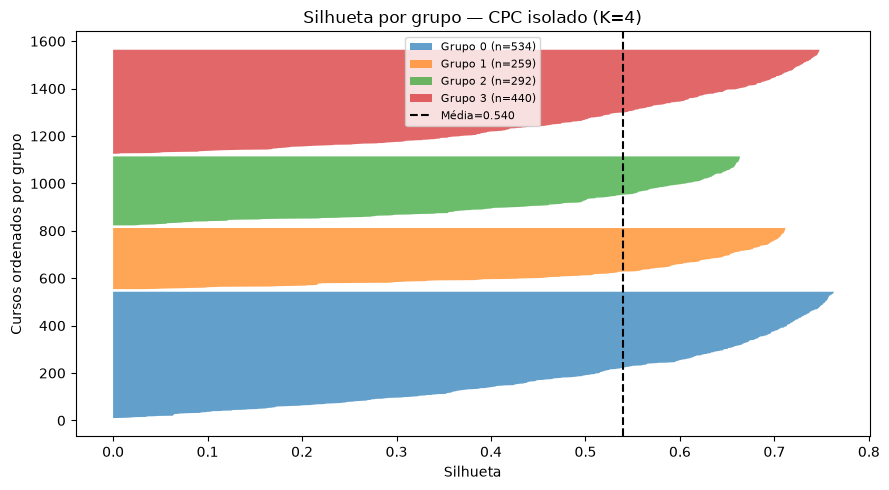

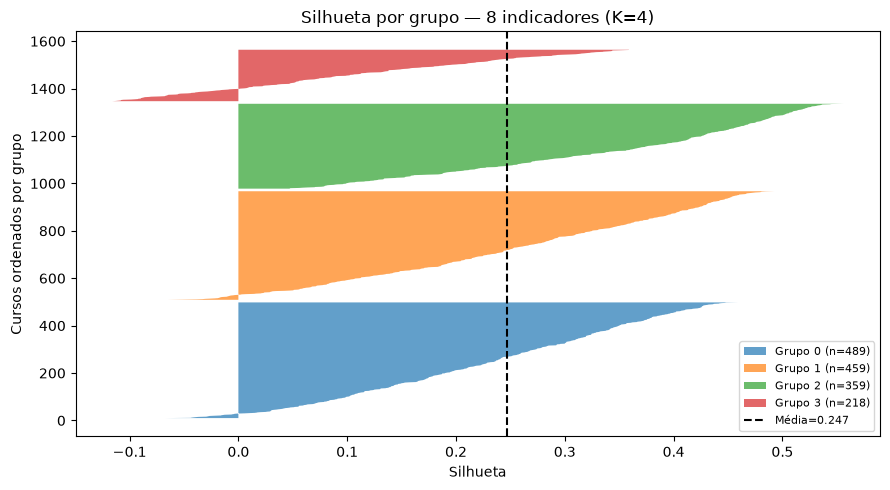

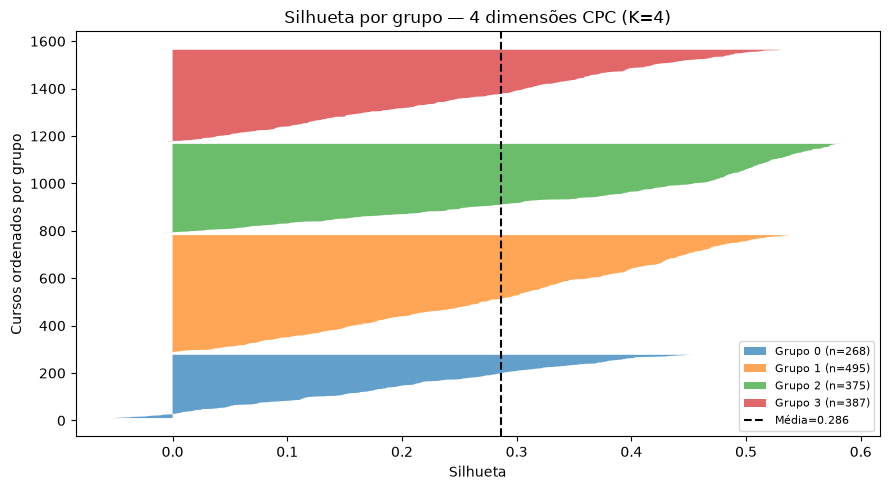

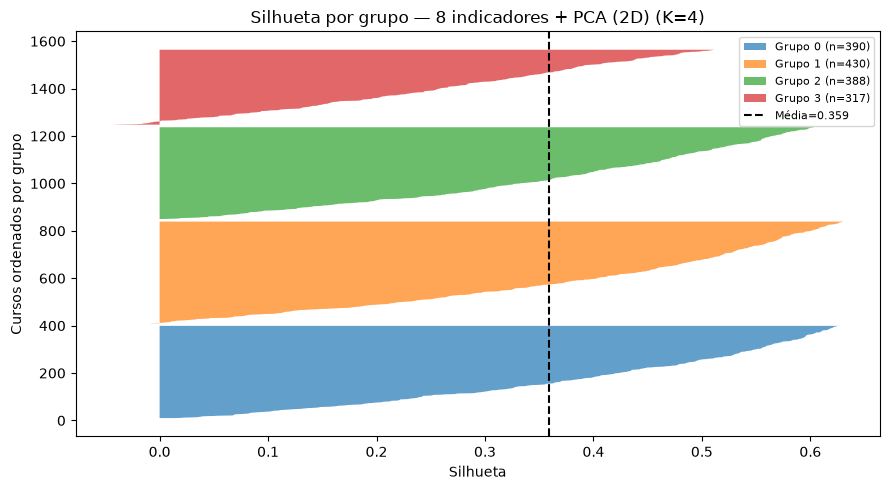

In [9]:
for cen, info in modelos_ref.items():
    X=info['proc']['treino']; y=info['modelo'].labels_
    if len(np.unique(y))<2: continue
    sil=silhouette_samples(X,y)
    fig,ax=plt.subplots(figsize=(9,5))
    pos=10
    for grupo in sorted(np.unique(y)):
        valores=np.sort(sil[y==grupo]); n=len(valores)
        ax.fill_betweenx(np.arange(pos,pos+n),0,valores,alpha=.7,label=f'Grupo {grupo} (n={n})')
        pos+=n+10
    ax.axvline(sil.mean(),ls='--',color='black',label=f'Média={sil.mean():.3f}')
    ax.set(title=f'Silhueta por grupo — {CENARIOS[cen]} (K={K_PARA_DETALHAR[cen]})',xlabel='Silhueta',ylabel='Cursos ordenados por grupo')
    ax.legend(fontsize=8,loc='best');fig.tight_layout()
    fig.savefig(PASTA_SAIDA/f'04_silhueta_grupos_{cen}.png',dpi=150)
    plt.show()

## 10 — Dispersão PCA com centroides

Para C1, o gráfico é unidimensional (CPC padronizado). Para C2 e C3, o PCA **serve somente para visualizar** os grupos ajustados no espaço original, com os centroides projetados no mesmo plano. Para C4, o PCA faz parte do próprio modelo. A separação visual em duas dimensões pode ocultar diferenças presentes nas dimensões restantes.

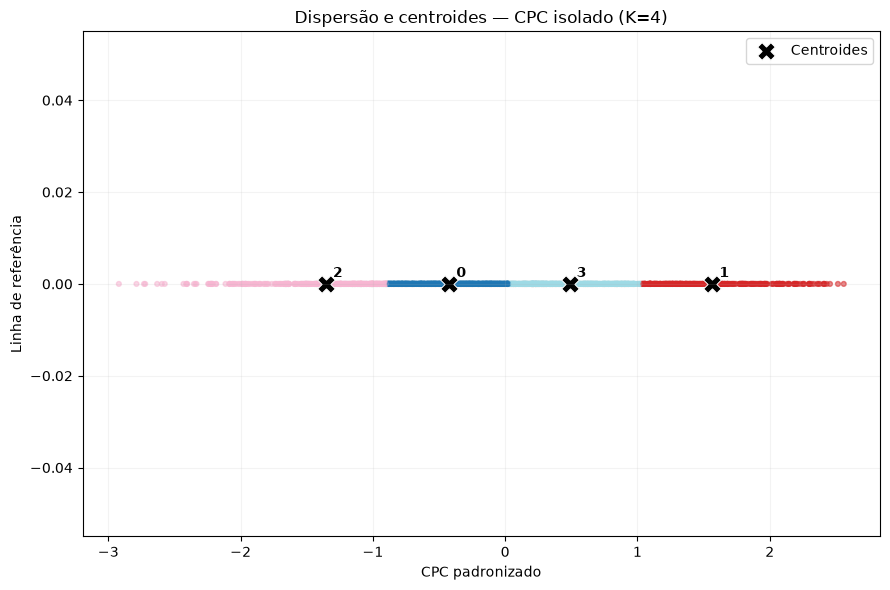

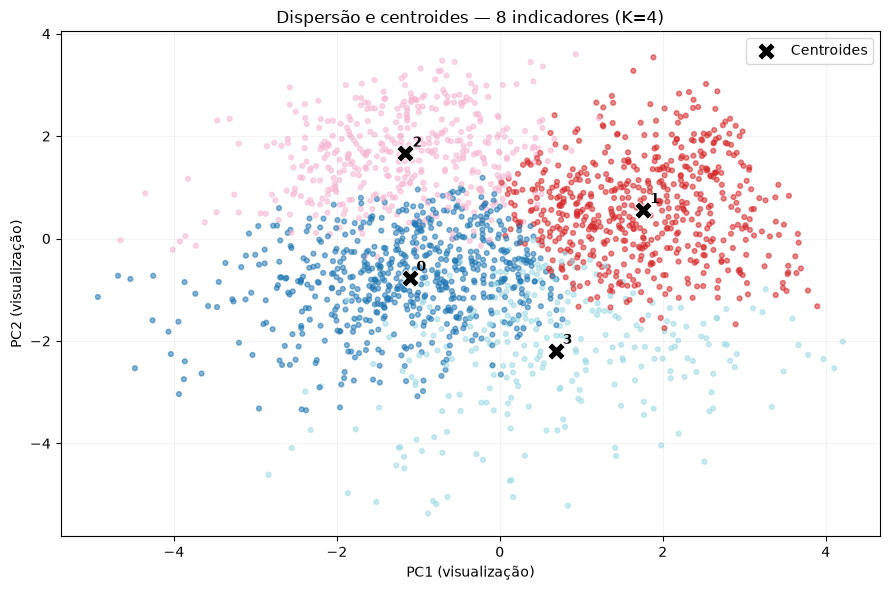

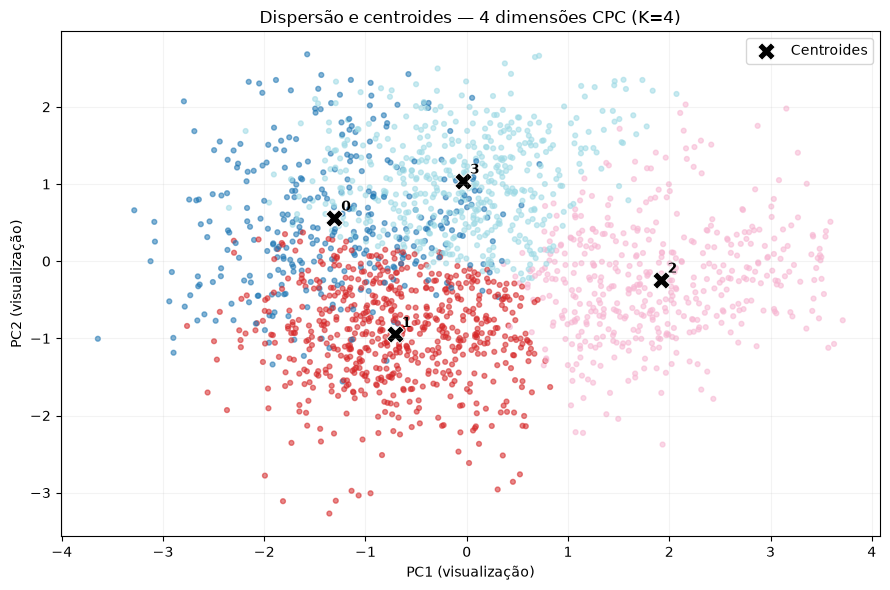

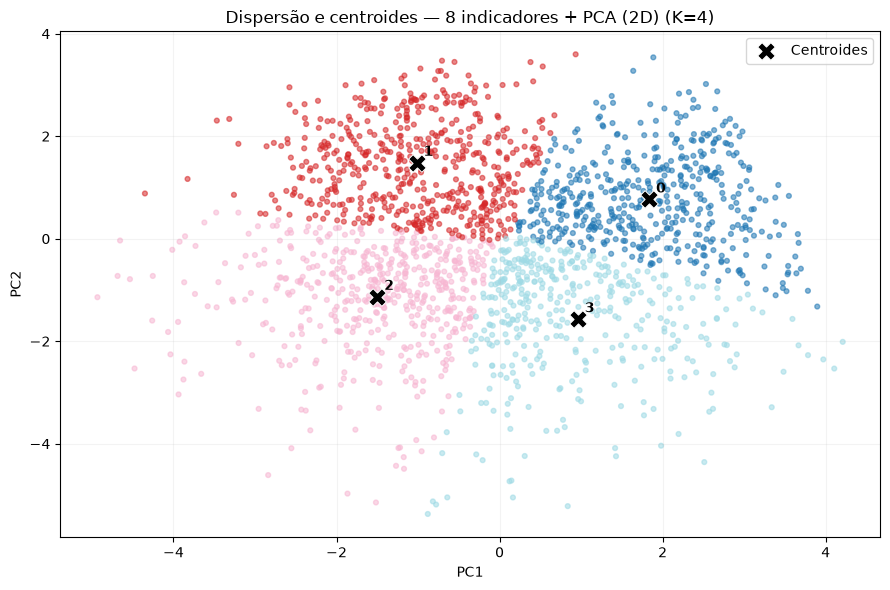

In [10]:
for cen, info in modelos_ref.items():
    proc=info['proc']; mod=info['modelo']; X=proc['todos']; labels=info['rotulos']
    if X.shape[1]==1:
        x=X[:,0]; y=np.zeros(len(x)); cx=mod.cluster_centers_[:,0];cy=np.zeros(len(cx))
        eixo_x,eixo_y='CPC padronizado','Linha de referência'
    elif cen=='C4_PCA':
        x,y=X[:,0],X[:,1];cx,cy=mod.cluster_centers_[:,0],mod.cluster_centers_[:,1]
        eixo_x,eixo_y='PC1','PC2'
    else:
        pca_vis=PCA(n_components=2).fit(proc['treino'])
        xy=pca_vis.transform(X);cxy=pca_vis.transform(mod.cluster_centers_)
        x,y=xy[:,0],xy[:,1];cx,cy=cxy[:,0],cxy[:,1]
        eixo_x,eixo_y='PC1 (visualização)','PC2 (visualização)'
    fig,ax=plt.subplots(figsize=(9,6))
    ax.scatter(x,y,c=labels,cmap='tab20',s=12,alpha=.55)
    ax.scatter(cx,cy,c='black',marker='X',s=160,edgecolors='white',linewidths=.7,label='Centroides')
    for j,(xx,yy) in enumerate(zip(cx,cy)): ax.annotate(str(j),(xx,yy),xytext=(5,5),textcoords='offset points',weight='bold')
    ax.set(title=f'Dispersão e centroides — {CENARIOS[cen]} (K={K_PARA_DETALHAR[cen]})',xlabel=eixo_x,ylabel=eixo_y)
    ax.legend();ax.grid(alpha=.15);fig.tight_layout()
    fig.savefig(PASTA_SAIDA/f'05_dispersao_centroides_{cen}.png',dpi=160)
    plt.show()

## 11 — Perfis médios dos grupos

Este gráfico usa médias **dos cursos efetivamente atribuídos** a cada grupo na base elegível, em vez de valores reconstruídos do PCA. Para facilitar a leitura entre indicadores, as médias são padronizadas em relação à média e ao desvio-padrão da população elegível. Valores positivos indicam indicadores acima da média desse escopo.

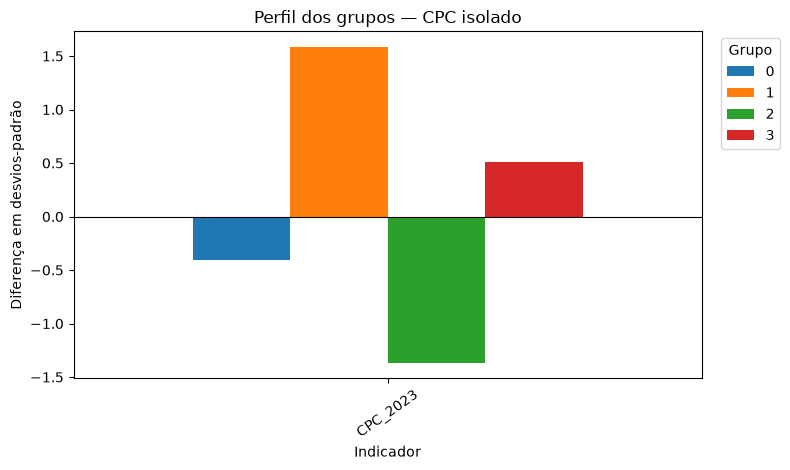

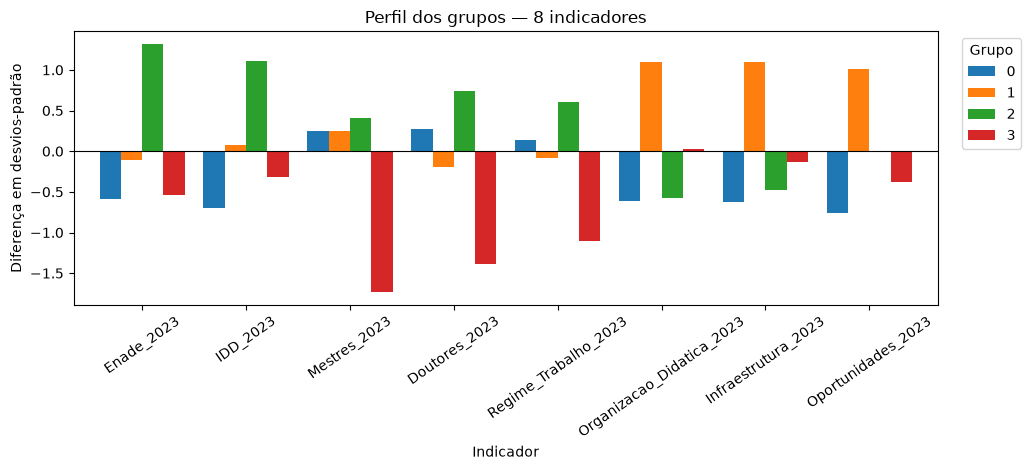

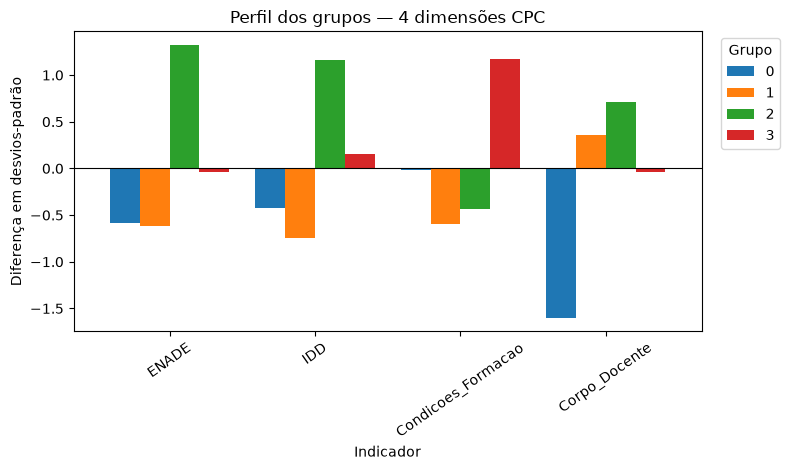

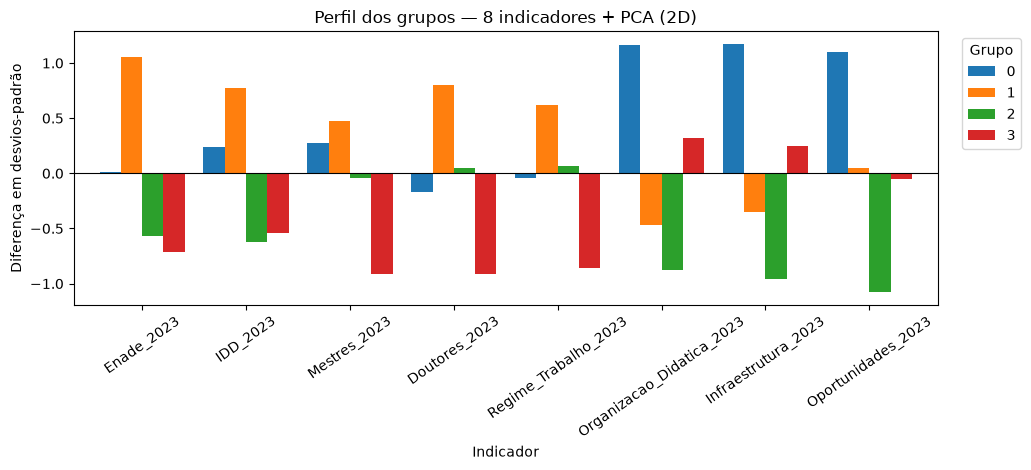

In [11]:
for cen, perfil in perfis_grupos.items():
    dados=dados_cenario(df_analise,cen)
    media=dados.mean(); desvio=dados.std(ddof=0).replace(0,np.nan)
    z=(perfil-media)/desvio
    fig,ax=plt.subplots(figsize=(max(8,len(z.columns)*1.3),4.8))
    z.T.plot(kind='bar',ax=ax,width=.82)
    ax.axhline(0,color='black',linewidth=.8)
    ax.set(title=f'Perfil dos grupos — {CENARIOS[cen]}',ylabel='Diferença em desvios-padrão',xlabel='Indicador')
    ax.legend(title='Grupo',bbox_to_anchor=(1.02,1),loc='upper left')
    ax.tick_params(axis='x',rotation=35)
    fig.tight_layout()
    fig.savefig(PASTA_SAIDA/f'06_perfil_grupos_{cen}.png',dpi=160,bbox_inches='tight')
    plt.show()

## 12 — Cursos da PUC-Rio e estabilidade local (quando presentes)

Identifica os registros com código da IES 528. Mostra, para cada cenário, o grupo de cada curso da PUC-Rio na execução de referência e o Jaccard médio da composição do grupo ao longo das 30 divisões. O Jaccard usa conjuntos de cursos, sem comparar números arbitrários de rótulos. Não há comparação temporal aqui.

In [12]:
mask_puc=pd.to_numeric(df_analise['Código da IES'],errors='coerce').eq(CODIGO_IES_PUC)
indices_puc=df_analise.index[mask_puc]
linhas_puc=[]
if len(indices_puc)==0:
    print('Nenhum curso da PUC-Rio no escopo elegível.')
else:
    for idx in indices_puc:
        reg=df_analise.loc[idx]
        for cen in CENARIOS:
            ref=rotulos_detalhe[cen][SEMENTE_REFERENCIA]
            grupo=ref.loc[idx]
            membros_ref=set(ref.index[ref.eq(grupo)])
            jac=[]
            for s,serie in rotulos_detalhe[cen].items():
                membros=set(serie.index[serie.eq(serie.loc[idx])])
                jac.append(len(membros & membros_ref)/len(membros | membros_ref))
            linhas_puc.append({'Indice':idx,'IES':reg['Código da IES'],
                'Curso':reg['Código do Curso'],'Area_2023':reg['Area_2023'],
                'Cenario':cen,'Grupo_referencia':grupo,
                'Tamanho_grupo_ref':len(membros_ref),'Jaccard_medio':np.mean(jac),
                'Jaccard_minimo':np.min(jac)})
resumo_puc=pd.DataFrame(linhas_puc)
if len(resumo_puc): display(resumo_puc.round(4))

,Indice,IES,Curso,Area_2023,Cenario,Grupo_referencia,Tamanho_grupo_ref,Jaccard_medio,Jaccard_minimo
0,133,528,59962,21,C1_CPC,0,676,0.9367,0.8932
1,133,528,59962,21,C2_8IND,3,276,0.9525,0.8990
2,133,528,59962,21,C3_4DIM,0,334,0.9213,0.8534
3,133,528,59962,21,C4_PCA,3,398,0.8321,0.7006
4,435,528,29445,5710,C1_CPC,1,309,0.9899,0.9810
5,435,528,29445,5710,C2_8IND,2,436,0.9874,0.9642
6,435,528,29445,5710,C3_4DIM,2,456,0.9804,0.9620
7,435,528,29445,5710,C4_PCA,0,481,0.6888,0.0030
8,801,528,29446,5806,C1_CPC,3,557,0.9678,0.9355
9,801,528,29446,5806,C2_8IND,1,571,0.9780,0.9300


## 13 — Síntese e exportação

Os arquivos ficam em `resultados_notebook_05/<escopo>/`. Compare **qualidade, estabilidade, tamanho dos grupos e interpretabilidade**. Evite eleger automaticamente um vencedor pela maior silhueta entre espaços distintos.

**Limitações a registrar na discussão:** base de 2023, possíveis diferenças de escala e dimensionalidade, CPC isolado não multidimensional, reuso de observações na avaliação de estabilidade, seleção exploratória de K sem teste final independente, e ausência ainda dos cenários temporais B e C.

In [13]:
tabelas={'01_diagnostico_elegiveis':pd.DataFrame([{'Escopo':nome_escopo,
    'Registros_originais':len(df_escopo),'Registros_elegiveis':len(df_analise),
    'Registros_excluidos':len(df_escopo)-len(df_analise)}]),
    '02_log_exploracao_k':log_exploracao,'03_resumo_k':resumo_k,
    '04_quadro_k':quadro_k,'05_log_30_repeticoes':log_detalhe,
    '06_ari_pares':df_ari,'07_resumo_ari':resumo_ari,
    '08_resumo_detalhe':resumo_detalhe}
if len(resumo_puc): tabelas['09_puc_rio']=resumo_puc
for cen in CENARIOS:
    tabelas[f'centroides_{cen}']=centroides_tabelas[cen]
    tabelas[f'perfis_{cen}']=perfis_grupos[cen].reset_index()
for nome,tabela in tabelas.items():
    destino=PASTA_SAIDA/(nome+'.csv')
    tabela.to_csv(destino,index=False,sep=';',decimal=',',encoding='utf-8-sig')
print('Arquivos CSV:',len(tabelas),'| pasta:',PASTA_SAIDA)
print('Figuras PNG:',len(list(PASTA_SAIDA.glob('*.png'))))
print('\nSíntese dos K detalhados:')
display(resumo_detalhe.round(4))

Arquivos CSV: 17 | pasta: g:\Meu Drive\Mestrado _ Eng_Ind\IND2622 - Ciencia de dados para processos de negocios\Trabalho final - CPC (escolhido)\Projeto_CPC_PUC_Rio_2026\resultados_notebook_05\BASE_COMPLETA
Figuras PNG: 15

Síntese dos K detalhados:


,Cenario,K,Silhueta_teste_media,Silhueta_teste_dp,DB_teste_medio,Menor_grupo_min,ARI_medio,ARI_dp,ARI_minimo,ARI_mediana,Comparacoes
0,C1_CPC,4,0.5327,0.0156,0.5459,235,0.9638,0.0266,0.8813,0.9690,435
1,C2_8IND,4,0.2366,0.0117,1.3744,213,0.9609,0.0163,0.9036,0.9635,435
2,C3_4DIM,4,0.2745,0.0105,1.1810,259,0.9392,0.0221,0.8492,0.9422,435
3,C4_PCA,4,0.3461,0.0125,0.9443,310,0.8684,0.0767,0.6645,0.8736,435


## 14 — Roteiro de discussão com a professora

1. **C1:** a estratificação por CPC isolado produz grupos, mas perde a informação multidimensional?
2. **C2:** os oito indicadores distinguem perfis acadêmicos com silhueta, DBI e estabilidade satisfatórios?
3. **C3:** as quatro dimensões ponderadas tornam a interpretação mais clara sem perda importante de estabilidade?
4. **C4:** reduzir os oito indicadores a duas componentes melhora a geometria do agrupamento ou apenas facilita a visualização?
5. **K:** como mudam a silhueta, DBI, inércia, tamanho dos grupos e ARI de K=2 a K=20?
6. **Escopo:** o que muda ao passar da base completa para cada área? Não comparar números absolutos sem considerar amostra e espaço.
7. **Próximos passos:** validação independente de configurações selecionadas, ampliação por áreas e cenários temporais B/C.

**Reprodutibilidade:** registrar versão do Python e bibliotecas, escopo, lista de cursos elegíveis, K selecionados, sementes e pasta de resultados.

In [14]:
import sys, sklearn, matplotlib
print('Python:',sys.version.split()[0])
print('pandas:',pd.__version__,'| numpy:',np.__version__)
print('scikit-learn:',sklearn.__version__,'| matplotlib:',matplotlib.__version__)
print('Escopo:',nome_escopo,'| N elegível:',len(df_analise))
print('Sementes exploração:',SEMENTES_EXPLORACAO)
print('Sementes confirmação:',SEMENTES_CONFIRMACAO)
print('K detalhados:',K_PARA_DETALHAR)

Python: 3.14.7
pandas: 3.0.6 | numpy: 2.5.3
scikit-learn: 1.9.1 | matplotlib: 3.11.2
Escopo: BASE_COMPLETA | N elegível: 1907
Sementes exploração: [42, 43, 44, 45, 46]
Sementes confirmação: [42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71]
K detalhados: {'C1_CPC': 4, 'C2_8IND': 4, 'C3_4DIM': 4, 'C4_PCA': 4}
